<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 10: L2, Dropout and Early Stopping Comparison

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Evaluate and compare regularization strategies (L2 penalty, Dropout, and Early Stopping) to mitigate overfitting on high-dimensional data.


### Task 1: Synthesize Noisy Overfitting Benchmark Dataset


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X_raw, y_raw = make_classification(n_samples=240, n_features=20, n_informative=8,
                                   n_redundant=8, flip_y=0.15, random_state=42)

X_tr, X_val, y_tr, y_val = train_test_split(X_raw, y_raw, test_size=0.35, random_state=42)

X_train_t = torch.tensor(X_tr, dtype=torch.float32)
y_train_t = torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

print(f"Training Samples: {len(X_tr)} (Features: 20), Validation Samples: {len(X_val)}")


Training Samples: 156 (Features: 20), Validation Samples: 84


### Task 2: Train Baseline, L2 Regularized, Dropout, and Early Stopped Models


In [2]:
def build_model(dropout_rate=0.0):
    return nn.Sequential(
        nn.Linear(20, 64),
        nn.ReLU(),
        nn.Dropout(dropout_rate),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Dropout(dropout_rate),
        nn.Linear(32, 1)
    )

def train_config(model, l2_weight=0.0, early_stop=False, epochs=150):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=l2_weight)
    train_hist, val_hist = [], []
    best_val = float('inf')
    best_weights = None

    for ep in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(X_train_t)
        loss = criterion(out, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            v_loss = criterion(model(X_val_t), y_val_t).item()

        train_hist.append(loss.item())
        val_hist.append(v_loss)

        if early_stop:
            if v_loss < best_val:
                best_val = v_loss
                best_weights = model.state_dict()

    if early_stop and best_weights:
        model.load_state_dict(best_weights)

    return train_hist, val_hist

# 1. Baseline Overfit
m_base = build_model(dropout_rate=0.0)
tr_base, val_base = train_config(m_base, l2_weight=0.0)

# 2. L2 Regularization (Weight Decay)
m_l2 = build_model(dropout_rate=0.0)
tr_l2, val_l2 = train_config(m_l2, l2_weight=0.015)

# 3. Dropout (p = 0.4)
m_drop = build_model(dropout_rate=0.4)
tr_drop, val_drop = train_config(m_drop, l2_weight=0.0)

# 4. Early Stopping
m_es = build_model(dropout_rate=0.0)
tr_es, val_es = train_config(m_es, early_stop=True)

print("Training completed across all 4 regularization variants.")


Training completed across all 4 regularization variants.


### Task 3: Comparative Regularization Validation Loss Analysis


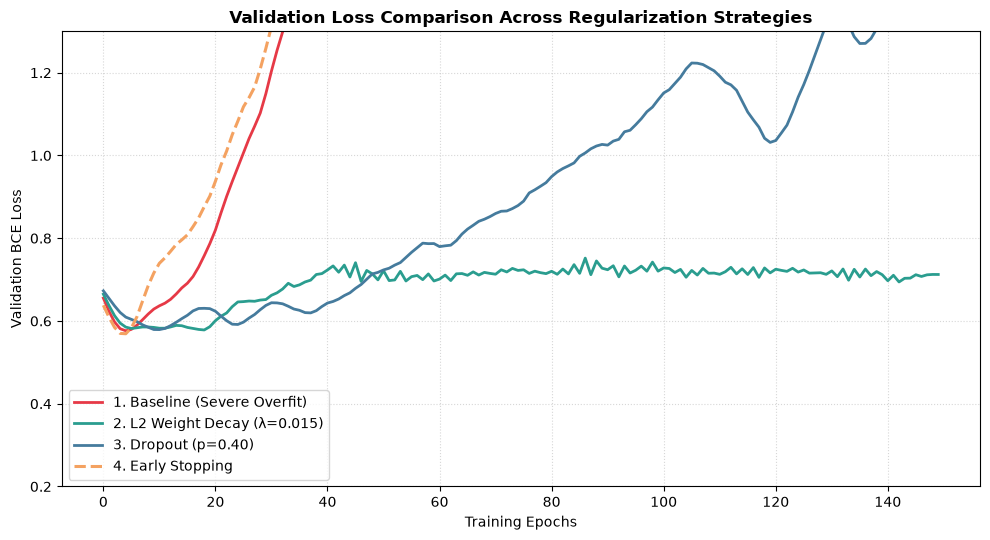

In [3]:
plt.figure(figsize=(10, 5.5))
plt.plot(val_base, color='#e63946', lw=2, label='1. Baseline (Severe Overfit)')
plt.plot(val_l2, color='#2a9d8f', lw=2, label='2. L2 Weight Decay (λ=0.015)')
plt.plot(val_drop, color='#457b9d', lw=2, label='3. Dropout (p=0.40)')
plt.plot(val_es, color='#f4a261', lw=2.2, linestyle='--', label='4. Early Stopping')

plt.title("Validation Loss Comparison Across Regularization Strategies", fontweight='bold', fontsize=12)
plt.xlabel("Training Epochs")
plt.ylabel("Validation BCE Loss")
plt.ylim(0.2, 1.3)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()
